# Выручка по тарифам и скидкам

Три вопроса: из каких тарифов складывается выручка, как менялась доля скидок и нулевых платежей, и как первая оплата
(по прайсу или со скидкой, короткий или длинный тариф) связана с LTV и удержанием когорты.
Суммы в тайваньских долларах (NTD), без отмен, без дисконтирования. Теория: `docs/ltv.md`.

Прайс по тарифам разной длины сравнивается через цену за 30 дней: оплата / длина тарифа × 30.
Связь первой оплаты с удержанием это наблюдение, а не эксперимент: скидки получают не случайные клиенты.

In [1]:
import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

P = "/workspace/data/processed/"
C_FROM, C_TO, MAX_AGE = "2015-07-01", "2016-03-01", 12
INK, BLUE, ORANGE, GREEN = "#2b2f36", "#0072B2", "#E69F00", "#009E73"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

con = duckdb.connect()
con.execute(
    "SET memory_limit='4GB'; SET threads=2; SET enable_progress_bar=false; "
    "SET temp_directory='/workspace/data/_duckdb_tmp'"
)
for name, file in [("tr", "transactions"), ("act", "active_months")]:
    con.execute(f'''
        CREATE VIEW {name} AS
        SELECT *
        FROM '{P}{file}.parquet'
    ''')

## Тарифы: откуда выручка
Для каждой длины тарифа: сколько транзакций и клиентов, какая доля выручки, средняя цена по прайсу, средняя оплата
и цена за 30 дней (только платные транзакции тарифов длиннее нуля дней).

In [2]:
plans = con.sql('''
    WITH plan_stats AS (
        SELECT
            payment_plan_days,
            count(*) AS transactions,
            count(DISTINCT msno) AS clients,
            sum(actual_amount_paid) AS revenue,
            avg(plan_list_price) AS avg_list,
            avg(actual_amount_paid) AS avg_paid,
            avg(actual_amount_paid * 30.0 / payment_plan_days)
                FILTER (WHERE payment_plan_days > 0 AND actual_amount_paid > 0) AS paid_per_30d
        FROM tr
        WHERE is_cancel = 0
        GROUP BY 1
    ),
    total AS (
        SELECT sum(revenue) AS total_revenue
        FROM plan_stats
    )
    SELECT
        payment_plan_days,
        transactions,
        clients,
        round(revenue / 1e6, 1) AS revenue_mln,
        round(100 * revenue / total_revenue, 1) AS revenue_share_pct,
        round(avg_list, 0) AS avg_list,
        round(avg_paid, 0) AS avg_paid,
        round(paid_per_30d, 0) AS paid_per_30d
    FROM plan_stats
    CROSS JOIN total
    ORDER BY revenue DESC
    LIMIT 12
''').df()
plans

,payment_plan_days,transactions,clients,revenue_mln,revenue_share_pct,avg_list,avg_paid,paid_per_30d
0,30,19333638,1807101,2559.8,76.0,135.0,132.0,135.0
1,410,162236,124937,287.2,8.5,1770.0,1770.0,131.0
2,0,854136,492895,135.5,4.0,0.0,159.0,NaN
3,195,138801,89843,123.0,3.7,886.0,886.0,138.0
4,31,733485,225136,107.0,3.2,149.0,146.0,144.0
5,180,76172,38167,43.1,1.3,566.0,566.0,96.0
6,395,20543,16720,31.1,0.9,1515.0,1515.0,121.0
7,100,28252,18895,13.6,0.4,481.0,481.0,144.0
8,360,10144,8673,12.2,0.4,1200.0,1200.0,100.0
9,90,31440,28834,12.0,0.4,382.0,382.0,129.0


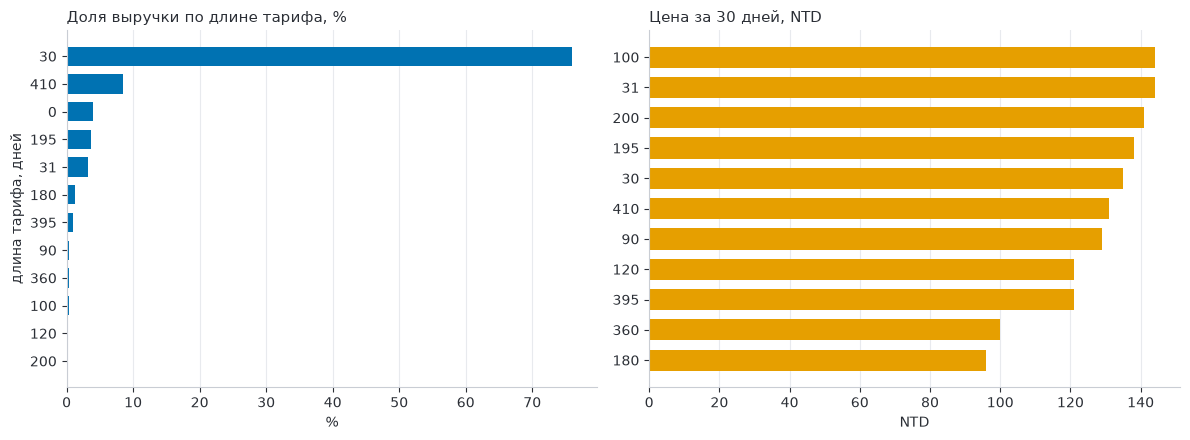

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
p = plans.sort_values("revenue_share_pct")
axes[0].barh(p.payment_plan_days.astype(str), p.revenue_share_pct, color=BLUE, height=0.7)
axes[0].set_title("Доля выручки по длине тарифа, %", loc="left", fontsize=11)
axes[0].set_xlabel("%")
axes[0].set_ylabel("длина тарифа, дней")
q = plans[plans.paid_per_30d > 0].sort_values("paid_per_30d")
axes[1].barh(q.payment_plan_days.astype(str), q.paid_per_30d, color=ORANGE, height=0.7)
axes[1].set_title("Цена за 30 дней, NTD", loc="left", fontsize=11)
axes[1].set_xlabel("NTD")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## Как менялись скидки и нулевые платежи
Доля транзакций по месяцам (без отмен): оплата 0 (пробные периоды и бонусы) и оплата со скидкой (меньше прайса, но больше нуля).

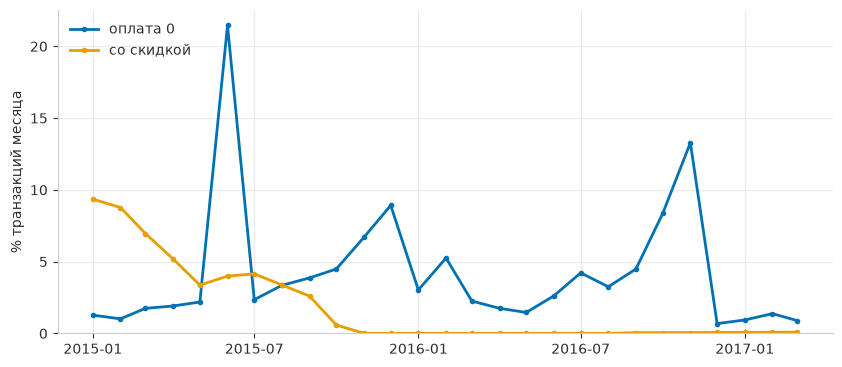

'  month  zero_pct  discount_pct\n2015-01       1.3           9.4\n2015-04       1.9           5.2\n2015-07       2.3           4.1\n2015-10       4.5           0.6\n2016-01       3.0           0.0\n2016-04       1.7           0.0\n2016-07       4.2           0.0\n2016-10       8.4           0.1\n2017-01       0.9           0.1'

In [4]:
types = con.sql('''
    SELECT
        date_trunc('month', transaction_date)::DATE AS month,
        100.0 * avg((actual_amount_paid = 0)::INT) AS zero_pct,
        100.0 * avg((actual_amount_paid > 0 AND actual_amount_paid < plan_list_price)::INT) AS discount_pct
    FROM tr
    WHERE is_cancel = 0
    GROUP BY 1
    ORDER BY 1
''').df()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(types.month, types.zero_pct, color=BLUE, lw=2, marker="o", ms=3, label="оплата 0")
ax.plot(types.month, types.discount_pct, color=ORANGE, lw=2, marker="o", ms=3, label="со скидкой")
ax.set_ylabel("% транзакций месяца")
ax.set_ylim(0, None)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(frameon=False, loc="upper left")
plt.show()
types.assign(month=types.month.dt.strftime("%Y-%m")).round(1).iloc[::3].to_string(index=False)

## Первая оплата и LTV когорты
Когорты первой платной подписки 2015-07 .. 2016-03 (каждая наблюдается 12 месяцев). Первая платная транзакция
клиента классифицируется двумя способами:
1. по цене: «по прайсу» (оплата равна прайсу), «со скидкой» (оплата меньше прайса), «выше прайса» (оплата больше прайса, в основном тариф 0 дней);
2. по длине тарифа: «короче 30 дней», «30–31 день», «длиннее 31 дня» (длинные тарифы оплачиваются сразу за несколько месяцев).

Для каждой группы: накопленная выручка на клиента и доля активных клиентов (подписка действует) в 3-м и 12-м месяцах.

In [5]:
def coh_cte(group_col: str) -> str:
    '''Строит часть запроса SQL, выбирающую клиентов когорт и группу первой платной транзакции.

    Args:
        group_col (str): `price_type` или `plan_type`.

    Returns:
        str: CTE с именем `coh` (столбцы `msno`, `cohort`, `grp`).
    '''
    return f'''
        first_pay AS (
            SELECT
                msno,
                date_trunc('month', transaction_date)::DATE AS cohort,
                CASE
                    WHEN actual_amount_paid < plan_list_price THEN 'со скидкой'
                    WHEN actual_amount_paid = plan_list_price THEN 'по прайсу'
                    ELSE 'выше прайса'
                END AS price_type,
                CASE
                    WHEN payment_plan_days < 30 THEN 'короче 30 дней'
                    WHEN payment_plan_days <= 31 THEN '30–31 день'
                    ELSE 'длиннее 31 дня'
                END AS plan_type
            FROM tr
            WHERE is_cancel = 0
                AND actual_amount_paid > 0
            QUALIFY row_number() OVER (
                PARTITION BY msno
                ORDER BY transaction_date, actual_amount_paid DESC
            ) = 1
        ),
        coh AS (
            SELECT
                msno,
                cohort,
                {group_col} AS grp
            FROM first_pay
            WHERE cohort BETWEEN DATE '{C_FROM}' AND DATE '{C_TO}'
        )
    '''


def ltv_by(group_col: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''Считает накопленную выручку на клиента и сводку по группам первой оплаты.

    Args:
        group_col (str): `price_type` или `plan_type`.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: накопленная выручка (группы в строках, возраст в столбцах)
            и сводка (клиентов, доля когорты, LTV на горизонтах 3, 6, 12 месяцев, доля активных).
    '''
    cte = coh_cte(group_col)
    sizes = con.sql(f'''
        WITH {cte}
        SELECT
            grp,
            count(*) AS size
        FROM coh
        GROUP BY grp
    ''').df().set_index("grp")["size"]
    rev = con.sql(f'''
        WITH {cte},
        pay AS (
            SELECT
                msno,
                date_trunc('month', transaction_date)::DATE AS pay_month,
                sum(actual_amount_paid) AS amount
            FROM tr
            WHERE is_cancel = 0
                AND actual_amount_paid > 0
            GROUP BY msno, 2
        )
        SELECT
            coh.grp,
            date_diff('month', coh.cohort, pay.pay_month) AS age,
            sum(pay.amount) AS revenue
        FROM coh
        JOIN pay USING (msno)
        WHERE pay.pay_month >= coh.cohort
            AND date_diff('month', coh.cohort, pay.pay_month) <= {MAX_AGE}
        GROUP BY coh.grp, 2
    ''').df()
    active = con.sql(f'''
        WITH {cte}
        SELECT
            coh.grp,
            date_diff('month', coh.cohort, act.month) AS age,
            count(*) AS active
        FROM coh
        JOIN act USING (msno)
        WHERE act.month >= coh.cohort
            AND date_diff('month', coh.cohort, act.month) IN (3, 12)
        GROUP BY coh.grp, 2
    ''').df()
    grid = rev.pivot(index="grp", columns="age", values="revenue").reindex(columns=range(MAX_AGE + 1)).fillna(0)
    cum = grid.div(sizes, axis=0).cumsum(axis=1)
    act_share = active.pivot(index="grp", columns="age", values="active").div(sizes, axis=0)
    summary = pd.DataFrame({
        "клиентов": sizes.astype(int),
        "доля когорты, %": (100 * sizes / sizes.sum()).round(1),
        "LTV 3 мес, NTD": cum[3].round(0),
        "LTV 6 мес, NTD": cum[6].round(0),
        "LTV 12 мес, NTD": cum[12].round(0),
        "активны в 3-м месяце, %": (100 * act_share[3]).round(1),
        "активны в 12-м месяце, %": (100 * act_share[12]).round(1),
    }).sort_values("клиентов", ascending=False)
    return cum.loc[summary.index], summary


def plot_cum(cum: pd.DataFrame, summary: pd.DataFrame, title: str):
    '''Рисует накопленную выручку на клиента по группам.

    Args:
        cum (pd.DataFrame): накопленная выручка (группы в строках, возраст в столбцах).
        summary (pd.DataFrame): сводка по группам (нужен размер группы для подписи).
        title (str): заголовок графика.
    '''
    fig, ax = plt.subplots(figsize=(10, 4.8))
    for (grp, row), col in zip(cum.iterrows(), [BLUE, ORANGE, GREEN]):
        ax.plot(row.index, row.values, color=col, lw=2, marker="o", ms=3,
                label=f"{grp} (клиентов: {summary.loc[grp, 'клиентов']:,})".replace(",", " "))
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("возраст когорты, месяцев")
    ax.set_ylabel("накопленная выручка на клиента, NTD")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(frameon=False, loc="upper left")
    plt.show()

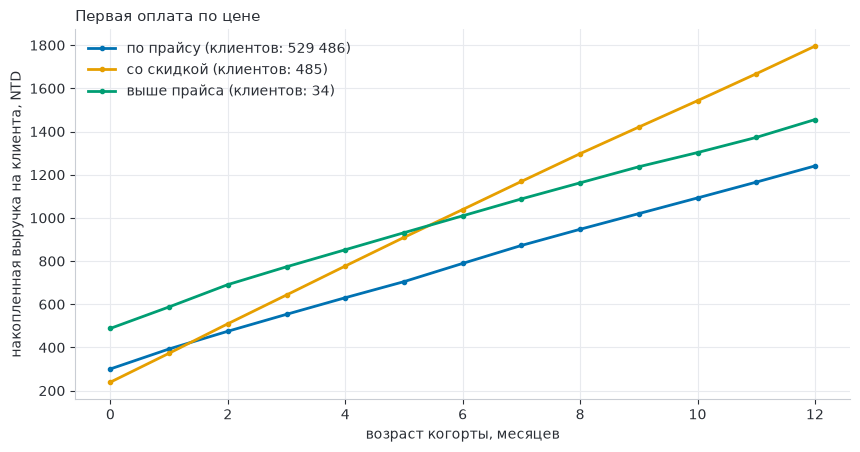

,клиентов,"доля когорты, %","LTV 3 мес, NTD","LTV 6 мес, NTD","LTV 12 мес, NTD","активны в 3-м месяце, %","активны в 12-м месяце, %"
grp,,,,,,,
по прайсу,529486,99.9,553.0,789.0,1241.0,82.4,74.4
со скидкой,485,0.1,643.0,1039.0,1795.0,95.5,89.1
выше прайса,34,0.0,774.0,1010.0,1455.0,94.1,70.6


In [6]:
cum_price, summary_price = ltv_by("price_type")
plot_cum(cum_price, summary_price, "Первая оплата по цене")
summary_price

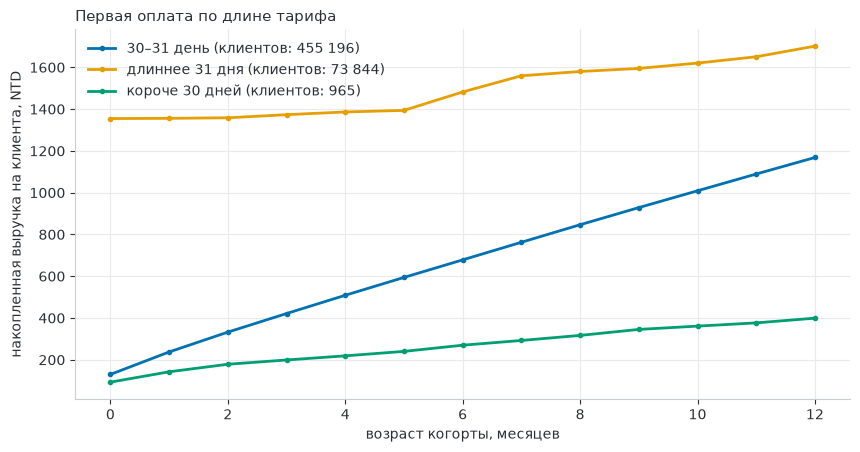

,клиентов,"доля когорты, %","LTV 3 мес, NTD","LTV 6 мес, NTD","LTV 12 мес, NTD","активны в 3-м месяце, %","активны в 12-м месяце, %"
grp,,,,,,,
30–31 день,455196,85.9,421.0,678.0,1168.0,79.7,72.8
длиннее 31 дня,73844,13.9,1373.0,1482.0,1701.0,99.7,85.3
короче 30 дней,965,0.2,199.0,270.0,399.0,24.0,21.5


In [7]:
cum_plan, summary_plan = ltv_by("plan_type")
plot_cum(cum_plan, summary_plan, "Первая оплата по длине тарифа")
summary_plan

## Выводы
- **Тарифы.** Тариф 30 дней даёт 76,0% выручки (19,3 млн транзакций, 1,8 млн клиентов). Тариф 410 дней 8,5% (125 тысяч клиентов), тариф 195 дней 3,7%. Платежи с тарифом 0 дней (прайс 0, оплата около 160 NTD) дают 4,0% выручки (135 млн NTD, 493 тысячи клиентов); что это за платежи, из описания данных неясно.
- **Цена за 30 дней.** Для тарифа 30 дней 135 NTD, для 31 дня 144 NTD. Длинные тарифы в основном дешевле за единицу времени: 180 дней 96 NTD (на 29% ниже), 360 дней 100 NTD, 395 дней 121 NTD, 410 дней 131 NTD. Зависимость не монотонная: тариф 195 дней стоит 138 NTD за 30 дней.
- **Скидки исчезли.** Доля транзакций со скидкой была 9,4% в январе 2015, 5,2% в апреле, 4,1% в июле, 0,6% в октябре 2015 и около нуля с января 2016. Доля нулевых платежей колеблется от 1% до 8% (по кварталам, пик 8,4% в октябре 2016).
- **Сравнить скидки по LTV нельзя.** В когортах 2015-07 .. 2016-03, пригодных для анализа (раньше действует левое цензурирование), первая оплата со скидкой у 485 клиентов из 529 тысяч (0,1%), с оплатой выше прайса у 40. Различия LTV (1795 NTD со скидкой против 1241 по прайсу) на таких размерах не интерпретируются.
- **Первый тариф.** 85,9% когорты начинают с тарифа 30–31 день, 13,9% с тарифа длиннее 31 дня, 0,2% с тарифа короче 30 дней. LTV за 12 месяцев: 1168, 1701 и 403 NTD. Доля активных в 3-м месяце: 79,7%, 99,7% и 24,6%, в 12-м месяце: 72,8%, 85,3% и 22,0%.
- **Осторожно с длинными тарифами.** Они оплачиваются сразу и действуют месяцами (410 дней покрывают все 12 месяцев), поэтому высокие активность и LTV этой группы в значительной мере механические. Это не доказывает, что такие клиенты лояльнее; для честного сравнения нужно смотреть, что происходит после окончания длинного тарифа.
- **Ограничения.** Все сравнения групп это наблюдения, а не эксперимент: тариф и скидку выбирают не случайные клиенты.